## Tying the two axes together

If delay propagates through aircraft rotations (axis 1), the share of delay minutes inherited from the previous flight should grow through the day: first-wave aircraft start fresh, evening aircraft carry what accumulated.

BTS reports a cause breakdown only for flights arriving 15+ minutes late, so this describes the delay of late flights. Causes are reported by airlines following BTS conventions. As a check, the five causes should add up to total arrival delay for those flights.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
con = duckdb.connect()
con.execute(f"CREATE OR REPLACE VIEW flights AS SELECT * FROM read_parquet('{(ROOT / 'data' / 'parquet').as_posix()}/*.parquet')")
con.sql("SELECT count(*) AS n_flights FROM flights")

┌───────────┐
│ n_flights │
│   int64   │
├───────────┤
│    605844 │
└───────────┘

In [2]:
import logging
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

BRAND = {"black": "#0D0D0D", "yellow": "#F5C518", "white": "#FFFFFF", "grey": "#8C8C8C"}
TITLE_FONT = ["Space Grotesk", "Inter 18pt", "DejaVu Sans"]

plt.rcParams.update({
    "figure.facecolor": BRAND["black"], "axes.facecolor": BRAND["black"], "savefig.facecolor": BRAND["black"],
    "text.color": BRAND["white"], "axes.labelcolor": BRAND["grey"],
    "xtick.color": BRAND["grey"], "ytick.color": BRAND["grey"],
    "axes.edgecolor": "#2A2A2A", "grid.color": "#2A2A2A", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "font.sans-serif": ["Inter 18pt", "DejaVu Sans"], "font.family": "sans-serif", "font.size": 10.5,
})

In [3]:
con.sql("""
    SELECT sum(carrier_delay + weather_delay + nas_delay + security_delay + late_aircraft_delay) AS cause_minutes,
           sum(arr_delay) AS arrival_delay_minutes,
           count(*) AS n_late_flights
    FROM flights
    WHERE NOT cancelled AND NOT diverted AND arr_delay >= 15 AND late_aircraft_delay IS NOT NULL
""").df()

,cause_minutes,arrival_delay_minutes,n_late_flights
0,7841298.0,7841595.0,122251


In [4]:
causes = con.sql("""
    WITH d AS (
        SELECT (CAST(crs_dep_hhmm AS INT) // 100) % 24 AS hr,
               carrier_delay, weather_delay, nas_delay, security_delay, late_aircraft_delay,
               carrier_delay + weather_delay + nas_delay + security_delay + late_aircraft_delay AS total_min
        FROM flights
        WHERE NOT cancelled AND NOT diverted AND arr_delay >= 15 AND late_aircraft_delay IS NOT NULL
    )
    SELECT hr,
           count(*) AS n_late_flights,
           round(100.0 * sum(late_aircraft_delay) / sum(total_min), 1) AS late_aircraft_pct,
           round(100.0 * sum(carrier_delay)       / sum(total_min), 1) AS carrier_pct,
           round(100.0 * (sum(nas_delay) + sum(weather_delay) + sum(security_delay)) / sum(total_min), 1) AS other_pct
    FROM d
    GROUP BY hr
    HAVING count(*) >= 500
    ORDER BY hr
""").df()
causes.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
hr,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0,21.0,22.0,23.0
n_late_flights,978.0,3227.0,4960.0,5431.0,4960.0,6296.0,6769.0,7021.0,7809.0,8161.0,9098.0,9574.0,11074.0,10526.0,10025.0,7366.0,5057.0,3137.0,625.0
late_aircraft_pct,16.3,14.3,14.3,25.0,31.6,34.5,34.7,38.8,42.6,41.8,43.6,42.2,43.4,45.5,50.5,52.0,46.9,44.6,39.6
carrier_pct,66.6,64.6,58.4,47.6,39.2,35.4,33.9,30.6,30.5,29.7,29.6,27.1,27.6,28.0,26.8,28.5,34.1,40.1,48.8
other_pct,17.1,21.1,27.4,27.4,29.2,30.1,31.4,30.6,26.9,28.5,26.8,30.7,29.0,26.5,22.7,19.5,19.0,15.3,11.6


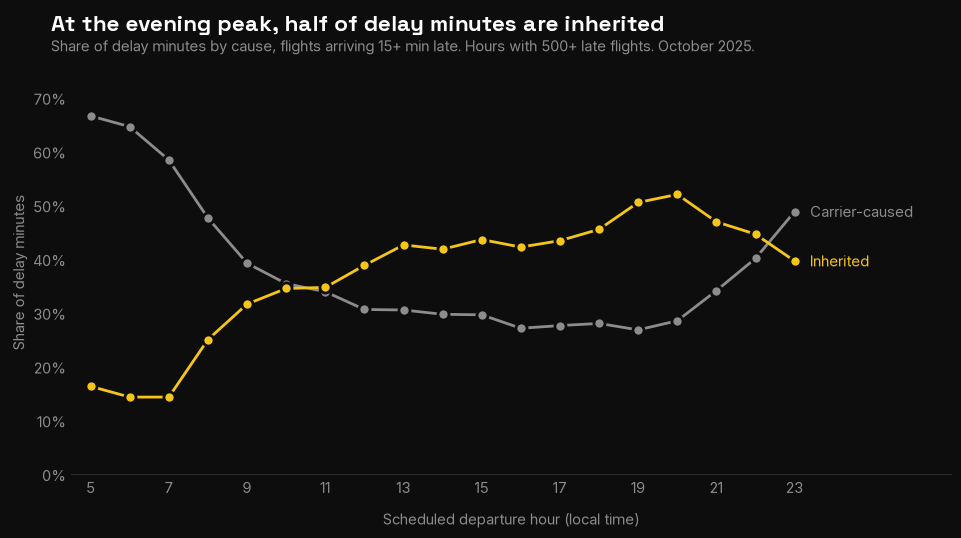

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.6))
ax.grid(axis="x", visible=False)
for col, color, label in [("carrier_pct", BRAND["grey"], "Carrier-caused"),
                          ("late_aircraft_pct", BRAND["yellow"], "Inherited")]:
    ax.plot(causes["hr"], causes[col], color=color, linewidth=2, marker="o", markersize=8,
            markerfacecolor=color, markeredgecolor=BRAND["black"], markeredgewidth=2)
    ax.text(causes["hr"].iloc[-1] + 0.4, causes[col].iloc[-1], label, color=color, va="center", fontsize=10.5)

ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylim(0, 75)
ax.set_xlim(4.5, 27)
ax.set_xticks(range(5, 24, 2))
ax.tick_params(length=0)
ax.set_xlabel("Scheduled departure hour (local time)", labelpad=10)
ax.set_ylabel("Share of delay minutes")

fig.text(0.07, 0.95, "At the evening peak, half of delay minutes are inherited", fontsize=16, fontweight="bold",
         fontfamily=TITLE_FONT, ha="left", va="top")
fig.text(0.07, 0.90, "Share of delay minutes by cause, flights arriving 15+ min late. Hours with 500+ late flights. October 2025.",
         fontsize=10.5, color=BRAND["grey"], ha="left", va="top")
fig.subplots_adjust(left=0.09, right=0.97, top=0.84, bottom=0.12)

fig.savefig(ROOT / "figures" / "delay_causes_by_hour.png", dpi=150)
plt.show()

### Findings

- Inherited delay (late aircraft) grows through the day: 14% of delay minutes for 6:00–7:00 departures, 35% around 10:00–11:00, and 50–52% at 19:00–20:00.
- Carrier-caused delay follows the opposite path: 58–66% in the first wave, falling below 30% from mid-afternoon.
- This matches the propagation mechanism of axis 1: aircraft start the day without accumulated delay and pass it along the rotation as the day goes on.
- Linking both axes: padding stays almost flat through the day (5.7–8.3 min on average) while the share of delay inherited from the previous flight triples, so schedules do not add margin where propagation is greatest.
- After 21:00 the inherited share falls again and the carrier-caused share rises (48.8% at 23:00, with only 625 late flights, so treat it with caution).
- Cause attribution is reported by airlines following BTS conventions and is only available for flights arriving 15+ minutes late.